<h1 style="text-align:center;background-color: #0A4A7A;COLOR: white; padding: 20px; border-radius: 10px;">
Online Retail Dataset Analysis
</h1>

This project will guide step by step through data loading, data cleaning, exploratory data analysis (EDA), and data visualization preparation using Python, NumPy, and Pandas.
Online Retail Dataset
•	Source: UCI Machine Learning Repository
•	Data type: Online retail transactions
•	Period: 1 December 2010 – 9 December 2011
•	Main goal: Understand sales, customers, products, and purchasing patterns.


1. Project objectives
By the end of this project, you should be able to:
•	Load a real-world dataset into Pandas.
•	Understand the dataset's structure and data types.
•	Identify and handle missing values and duplicate records.
•	Detect invalid values and potential outliers.
•	Create new columns using Pandas and NumPy.
•	Analyze revenue, products, countries, and customer purchasing behavior.
•	Summarize findings for a project report.


2. Understand the dataset columns
The dataset contains transaction-level information with these columns:
Column	      Meaning
InvoiceNo -  Invoice or transaction number
StockCode -	 Product identifier
Description- Product name or description
Quantity   - Number of items purchased
InvoiceDate- Date and time of the transaction
UnitPrice -  Price per item
CustomerID - Customer identifier
Country	Customer's country
Important: Negative quantities can represent returned or cancelled items, so do not automatically treat every negative quantity as an error. Likewise, missing customer IDs do not necessarily make a transaction unusable for sales analysis.


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step1- Import the required libraries
</h1>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 2 — Load the Online Retail dataset
</h1>

In [3]:
df = pd.read_excel("Online Retail.xlsx")
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 3 — Understand the dataset structure
</h1>

In [4]:
print("Dataset shape:", df.shape)
display(df.head())
display(df.tail())
print(df.columns.tolist())
df.info()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 4 — Check the statistical summary
</h1>

In [6]:
display(df.describe())

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [8]:
display(df.describe(include="all"))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


In [9]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 5 — Check for missing values
</h1>

In [10]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [11]:
missing_percent = (df.isnull().mean() * 100).round(2)

print(missing_percent.sort_values(ascending=False))


CustomerID     24.93
Description     0.27
StockCode       0.00
InvoiceNo       0.00
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
Country         0.00
dtype: float64


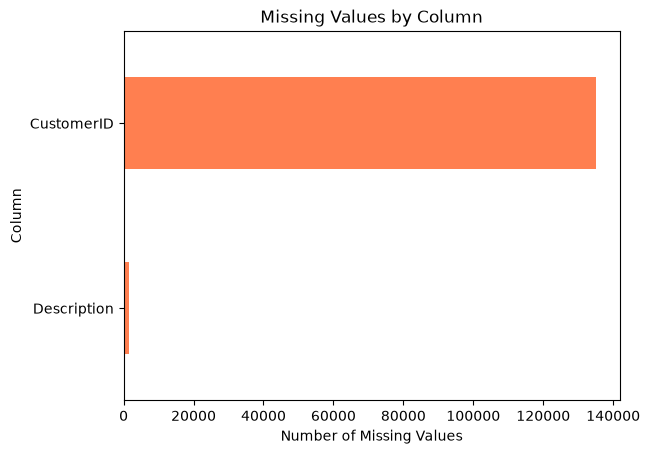

In [13]:
missing = df.isnull().sum()

missing[missing > 0].sort_values().plot(
    kind="barh",
    color="coral"
)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.show()


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 6 — Check and remove duplicate records
</h1>

In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


In [15]:
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (536641, 8)


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 7 — Clean column names and text values
</h1>

In [16]:
df.columns = df.columns.str.strip()

In [17]:
text_columns = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Country"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()


In [18]:
df["Description"] = df["Description"].str.upper()

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 8 — Correct the data types
</h1>

In [19]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

In [20]:
df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

In [21]:
df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"],
    errors="coerce"
)


In [22]:
df["CustomerID"] = df["CustomerID"].astype("string")

print(df.dtypes)


InvoiceNo              string
StockCode              string
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID             string
Country                string
dtype: object


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 9 — Handle missing values appropriately
</h1>

In [23]:
print(df.isna().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [24]:
required_columns = [
    "InvoiceNo",
    "StockCode",
    "InvoiceDate",
    "Quantity",
    "UnitPrice",
    "Country"
]

df = df.dropna(subset=required_columns).copy()

In [26]:
customer_df = df.dropna(subset=["CustomerID"]).copy()

print("All usable transactions:", len(df))
print("Transactions with customer IDs:", len(customer_df))

All usable transactions: 536641
Transactions with customer IDs: 401604


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 10 — Identify cancelled invoices
</h1>

In [27]:
is_cancelled = df["InvoiceNo"].str.upper().str.startswith(
    "C",
    na=False
)

cancelled_df = df[is_cancelled].copy()
sales_df = df[~is_cancelled].copy()

print("Cancellation rows:", len(cancelled_df))
print("Non-cancellation rows:", len(sales_df))

Cancellation rows: 9251
Non-cancellation rows: 527390


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 11 — Identify invalid quantities and prices
</h1>

In [29]:
invalid_quantity = sales_df[sales_df["Quantity"] <= 0]
invalid_price = sales_df[sales_df["UnitPrice"] <= 0]

print("Non-positive quantities:", len(invalid_quantity))
print("Non-positive prices:", len(invalid_price))

Non-positive quantities: 1336
Non-positive prices: 2512


In [30]:
valid_sales = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

print("Valid sales rows:", len(valid_sales))

Valid sales rows: 524878


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 12 — Detect outliers using NumPy and Pandas
</h1>

In [31]:
Q1 = valid_sales["Quantity"].quantile(0.25)
Q3 = valid_sales["Quantity"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = valid_sales[
    (valid_sales["Quantity"] < lower_bound) |
    (valid_sales["Quantity"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Quantity outliers:", len(outliers))

Lower bound: -14.0
Upper bound: 26.0
Quantity outliers: 27111


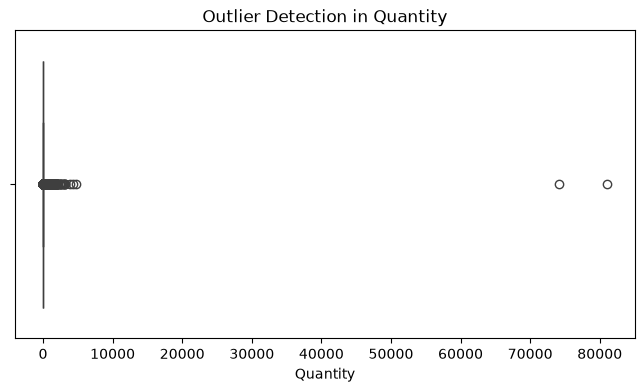

In [32]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=valid_sales, x="Quantity")

plt.title("Outlier Detection in Quantity")
plt.show()

In [33]:
valid_sales["QuantityFlag"] = np.where(
    (valid_sales["Quantity"] < lower_bound) |
    (valid_sales["Quantity"] > upper_bound),
    "Outlier",
    "Normal"
)

print(valid_sales["QuantityFlag"].value_counts())

QuantityFlag
Normal     497767
Outlier     27111
Name: count, dtype: int64


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 13 — Create new features using NumPy and Pandas
</h1>

In [34]:
valid_sales["TotalAmount"] = (
    valid_sales["Quantity"] *
    valid_sales["UnitPrice"]
)

display(
    valid_sales[
        ["InvoiceNo", "Quantity", "UnitPrice", "TotalAmount"]
    ].head()
)

,InvoiceNo,Quantity,UnitPrice,TotalAmount
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [35]:
valid_sales["Year"] = valid_sales["InvoiceDate"].dt.year
valid_sales["Month"] = valid_sales["InvoiceDate"].dt.month
valid_sales["Day"] = valid_sales["InvoiceDate"].dt.day
valid_sales["YearMonth"] = (
    valid_sales["InvoiceDate"].dt.to_period("M").astype(str)
)

display(valid_sales.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,QuantityFlag,TotalAmount,Year,Month,Day,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Normal,15.30,2010,12,1,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal,20.34,2010,12,1,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Normal,22.00,2010,12,1,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal,20.34,2010,12,1,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Normal,20.34,2010,12,1,2010-12


In [36]:
valid_sales["OrderSize"] = np.where(
    valid_sales["Quantity"] >= 10,
    "Bulk",
    "Regular"
)

print(valid_sales["OrderSize"].value_counts())

OrderSize
Regular    370741
Bulk       154137
Name: count, dtype: int64


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 14 — Perform final data-quality checks
</h1>

In [37]:
print("Final shape:", valid_sales.shape)

print("\nMissing values:")
print(valid_sales.isna().sum())

print("\nDuplicate rows:")
print(valid_sales.duplicated().sum())

print("\nData types:")
print(valid_sales.dtypes)

print("\nQuantity summary:")
print(valid_sales["Quantity"].describe())

print("\nPrice summary:")
print(valid_sales["UnitPrice"].describe())

print("\nTotal revenue:")
print(valid_sales["TotalAmount"].sum())

Final shape: (524878, 15)

Missing values:
InvoiceNo            0
StockCode            0
Description          0
Quantity             0
InvoiceDate          0
UnitPrice            0
CustomerID      132186
Country              0
QuantityFlag         0
TotalAmount          0
Year                 0
Month                0
Day                  0
YearMonth            0
OrderSize            0
dtype: int64

Duplicate rows:
0

Data types:
InvoiceNo               string
StockCode               string
Description             string
Quantity                 int64
InvoiceDate     datetime64[us]
UnitPrice              float64
CustomerID              string
Country                 string
QuantityFlag               str
TotalAmount            float64
Year                     int32
Month                    int32
Day                      int32
YearMonth                  str
OrderSize                  str
dtype: object

Quantity summary:
count    524878.000000
mean         10.616600
std         156.280031


In [39]:
assert valid_sales["Quantity"].gt(0).all()
assert valid_sales["UnitPrice"].gt(0).all()
assert valid_sales["InvoiceDate"].notna().all()

<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 15  — Save the cleaned dataset
</h1>

In [40]:
valid_sales.to_csv(
    "online_retail_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


<h1 style="text-align:center;background-color: #0A4A7A;COLOR: white; padding: 20px; border-radius: 10px;">
Exploratory Data Analysis (EDA)
</h1>

<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 16 — Analyze overall sales performance
</h1>

In [41]:
total_revenue = valid_sales["TotalAmount"].sum()

total_units = valid_sales["Quantity"].sum()

total_invoices = valid_sales["InvoiceNo"].nunique()

total_products = valid_sales["StockCode"].nunique()

total_customers = valid_sales["CustomerID"].nunique()

print("Total revenue (£):", round(total_revenue, 2))
print("Total units sold:", total_units)
print("Unique invoices:", total_invoices)
print("Unique products:", total_products)
print("Identified customers:", total_customers)

Total revenue (£): 10642110.8
Total units sold: 5572420
Unique invoices: 19960
Unique products: 3922
Identified customers: 4338


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 17 — Find the top-selling products
</h1>

In [42]:
top_products = (
    valid_sales
    .groupby("Description")
    .agg(
        UnitsSold=("Quantity", "sum"),
        Revenue=("TotalAmount", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_products)

,UnitsSold,Revenue
Description,,
DOTCOM POSTAGE,706,206248.77
REGENCY CAKESTAND 3 TIER,13851,174156.54
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
PARTY BUNTING,18283,99445.23
JUMBO BAG RED RETROSPOT,48371,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
POSTAGE,3150,78101.88
MANUAL,6985,77752.82


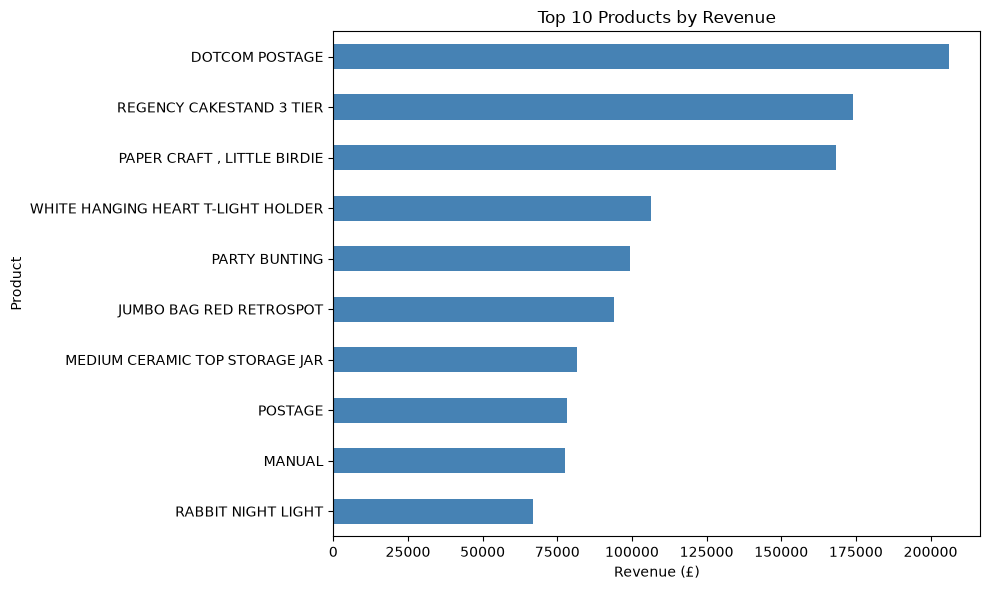

In [43]:
top_products["Revenue"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="steelblue"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 18 — Analyze sales by country
</h1>

In [44]:
country_sales = (
    valid_sales
    .groupby("Country")
    .agg(
        Revenue=("TotalAmount", "sum"),
        UnitsSold=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

display(country_sales.head(10))

,Revenue,UnitsSold,Orders
Country,,,
United Kingdom,9001744.094,4646906,18019
Netherlands,285446.340,200361,94
EIRE,283140.520,147007,288
Germany,228678.400,119154,457
France,209625.370,112060,392
Australia,138453.810,83891,57
Spain,61558.560,27933,90
Switzerland,57067.600,30617,54
Belgium,41196.340,23237,98


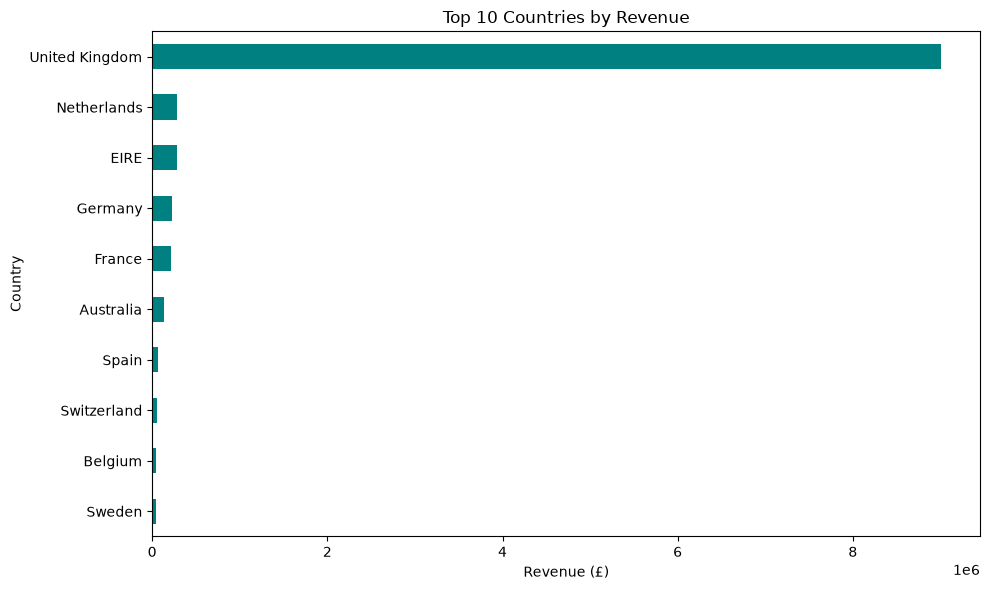

In [45]:
country_sales.head(10)["Revenue"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="teal"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 19 — Analyze monthly sales trends
</h1>

In [46]:
monthly_sales = (
    valid_sales
    .groupby("YearMonth")
    .agg(
        Revenue=("TotalAmount", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .sort_index()
)

display(monthly_sales)

,Revenue,Orders
YearMonth,,
2010-12,821452.730,1559
2011-01,689811.610,1086
2011-02,522545.560,1100
2011-03,716215.260,1454
2011-04,536968.491,1246
2011-05,769296.610,1681
2011-06,760547.010,1533
2011-07,718076.121,1475
2011-08,757841.380,1361


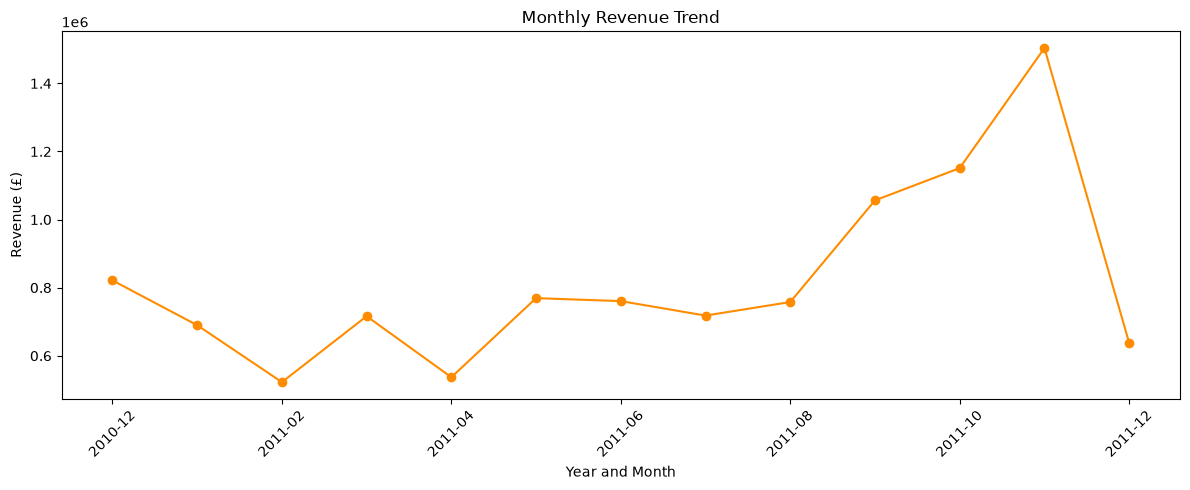

In [47]:
monthly_sales["Revenue"].plot(
    figsize=(12, 5),
    marker="o",
    color="darkorange"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Year and Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 20 — Analyze customer purchasing behavior
</h1>

In [48]:
customer_sales = (
    valid_sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        TotalSpent=("TotalAmount", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalUnits=("Quantity", "sum")
    )
    .sort_values("TotalSpent", ascending=False)
)

display(customer_sales.head(10))

,TotalSpent,TotalOrders,TotalUnits
CustomerID,,,
14646.0,280206.02,73,196915
18102.0,259657.30,60,64124
17450.0,194390.79,46,69973
16446.0,168472.50,2,80997
14911.0,143711.17,201,80240
12415.0,124914.53,21,77374
14156.0,117210.08,55,57768
17511.0,91062.38,31,64549
16029.0,80850.84,63,40108


<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 21 — Explore relationships between numerical variables
</h1>S

             Quantity  UnitPrice  TotalAmount
Quantity     1.000000  -0.003788     0.907402
UnitPrice   -0.003788   1.000000     0.137381
TotalAmount  0.907402   0.137381     1.000000


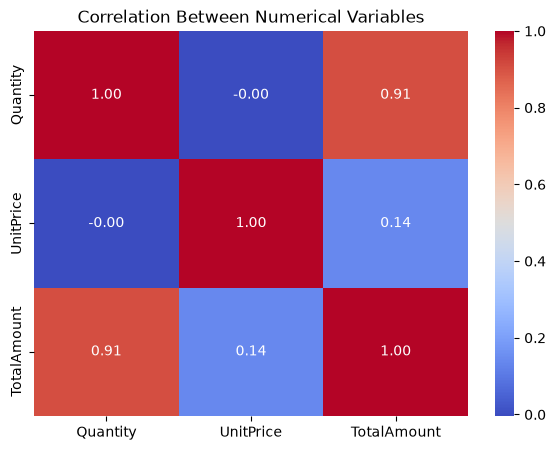

In [49]:
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "TotalAmount"
]

correlation = valid_sales[numeric_columns].corr()

print(correlation)

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.show()

<h1 style="background-color: #E3F2FD; border-left: 5px solid #1e90FF; color: #0d47a1; padding: 6px 15px; font-size: 15px; width: fit-content;border-radius: 0px 6px 6px 0px;">
Step 22 — Compare quantity and price distributions
</h1>

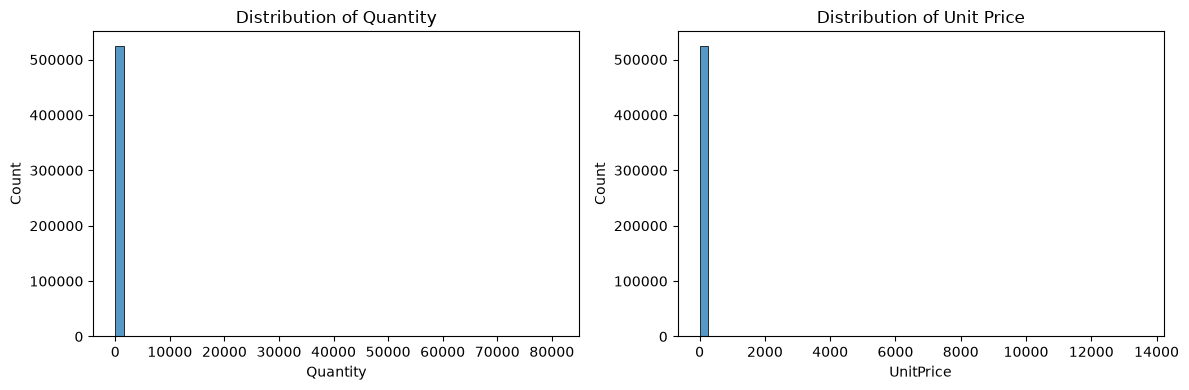

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=valid_sales,
    x="Quantity",
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Distribution of Quantity")

sns.histplot(
    data=valid_sales,
    x="UnitPrice",
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Distribution of Unit Price")

plt.tight_layout()
plt.show()